Saving Screenshot 2025-11-19 225721.png to Screenshot 2025-11-19 225721.png
HUFFMAN ENCODING RESULTS
----------------------------------------
Image Dimensions: 390 x 353
Unique Pixel Values: 241

Huffman Codes:
Pixel 0: 11101011001
Pixel 8: 11011001110011100
Pixel 17: 1111010010111001
Pixel 18: 11110100101110000
Pixel 19: 1101100111001111
Pixel 20: 11110100101110001
Pixel 21: 1100101
Pixel 22: 11011001110011101
Pixel 23: 110110011100110
Pixel 24: 1101000101100
Pixel 25: 11110000101010
Pixel 26: 1111011010010
Pixel 27: 1111011010011
Pixel 28: 11111
Pixel 29: 111010010100
Pixel 30: 1111011111001
Pixel 31: 1111000011111
Pixel 32: 1111010010100
Pixel 33: 1110111100001
Pixel 34: 110000
Pixel 35: 1101100111011
Pixel 36: 11110100101111
Pixel 37: 1101000101110
Pixel 38: 11011111011101
Pixel 39: 11000101
Pixel 40: 11110000111100
Pixel 41: 11101110001001
Pixel 42: 11110100101011
Pixel 43: 111100010
Pixel 44: 11101110001011
Pixel 45: 1101000101101
Pixel 46: 111010100
Pixel 47: 11011001110101
Pixe

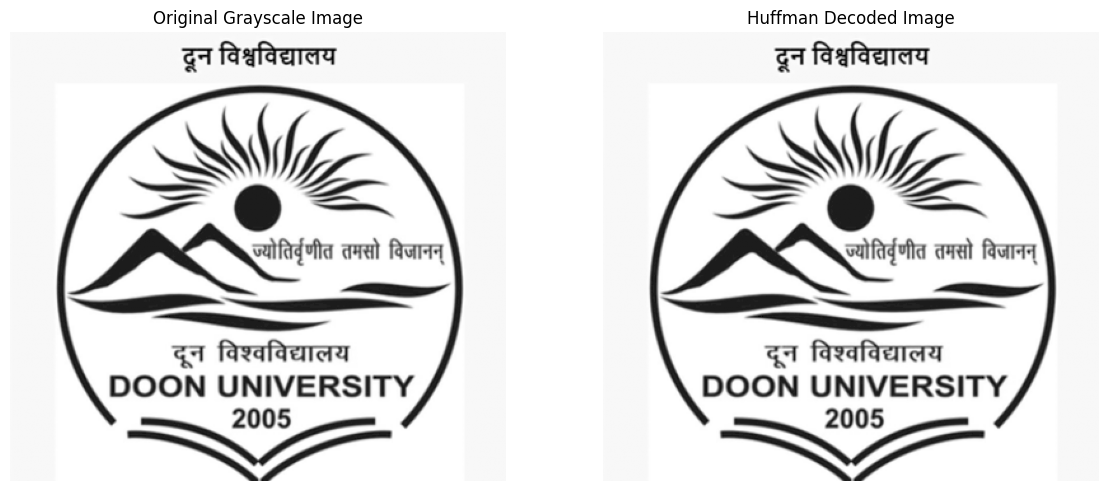


Decoded image saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

import cv2
import heapq
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from collections import Counter
from PIL import Image
import io

# STEP 1: Upload Image
uploaded = files.upload()
image_name = list(uploaded.keys())[0]

# STEP 2: Read and Convert Image to Grayscale
image = cv2.imdecode(
    np.frombuffer(uploaded[image_name], np.uint8),
    cv2.IMREAD_GRAYSCALE
)

if image is None:
    raise ValueError("Unable to read the uploaded image.")

height, width = image.shape
pixels = image.flatten()

# STEP 3: Calculate Frequency of Each Pixel
frequency = Counter(pixels)

# STEP 4: Create Huffman Tree
class Node:
    def __init__(self, pixel, freq):
        self.pixel = pixel
        self.freq = freq
        self.left = None
        self.right = None

    def __lt__(self, other):
        return self.freq < other.freq

heap = []

for pixel, freq in frequency.items():
    heapq.heappush(heap, Node(pixel, freq))

if len(heap) == 1:
    root = heap[0]
else:
    while len(heap) > 1:
        left = heapq.heappop(heap)
        right = heapq.heappop(heap)

        merged = Node(None, left.freq + right.freq)
        merged.left = left
        merged.right = right

        heapq.heappush(heap, merged)

    root = heap[0]

# STEP 5: Generate Huffman Codes
huffman_codes = {}

def generate_codes(node, code=""):
    if node is None:
        return

    if node.pixel is not None:
        huffman_codes[node.pixel] = code if code else "0"
        return

    generate_codes(node.left, code + "0")
    generate_codes(node.right, code + "1")

generate_codes(root)

# STEP 6: Encode Image
encoded_data = ''.join(huffman_codes[pixel] for pixel in pixels)

# STEP 7: Decode Encoded Data
decoded_pixels = []

if len(frequency) == 1:
    decoded_pixels = [next(iter(frequency.keys()))] * len(pixels)

else:
    current = root

    for bit in encoded_data:
        if bit == '0':
            current = current.left
        else:
            current = current.right

        if current is None:
            raise ValueError("Invalid Huffman encoded data.")

        if current.pixel is not None:
            decoded_pixels.append(current.pixel)
            current = root

# Verify decoded pixel count
if len(decoded_pixels) != len(pixels):
    raise ValueError("Decoding failed: Pixel count does not match.")

# STEP 8: Reconstruct Image
decoded_image = np.array(
    decoded_pixels,
    dtype=np.uint8
).reshape(height, width)
# STEP 9: Calculate Compression Ratio
original_size = pixels.size * 8
compressed_size = len(encoded_data)

compression_ratio = original_size / compressed_size if compressed_size else 0
compression_percentage = (1 - compressed_size / original_size) * 100

# STEP 10: Display Huffman Codes
print("HUFFMAN ENCODING RESULTS")
print("-" * 40)
print("Image Dimensions:", width, "x", height)
print("Unique Pixel Values:", len(frequency))
print("\nHuffman Codes:")

for pixel, code in sorted(huffman_codes.items()):
    print(f"Pixel {pixel}: {code}")

# STEP 11: Display Compression Results
print("\nCOMPRESSION DETAILS")
print("-" * 40)
print("Original Image Size (bits):", original_size)
print("Encoded Data Size (bits):", compressed_size)
print("Compression Ratio:", round(compression_ratio, 3))
print("Space Saving:", round(compression_percentage, 2), "%")

# STEP 12: Verify Decoding
if np.array_equal(image, decoded_image):
    print("\nImage Decoding: SUCCESS")
    print("Original and decoded images are identical.")
else:
    print("\nImage Decoding: FAILED")

# STEP 13: Display Original and Decoded Images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(decoded_image, cmap='gray')
plt.title("Huffman Decoded Image")
plt.axis("off")

plt.tight_layout()
plt.show()

# STEP 14: Save Reconstructed Image
cv2.imwrite("Huffman_Decoded_Image.png", decoded_image)

print("\nDecoded image saved successfully.")

files.download("Huffman_Decoded_Image.png")
